# Laminar model comparison with single-shell and BEM forwards

We’ll simulate a source on the white-matter surface of sub-104, then use free energy
to decide whether it came from the pial or white surface. We’ll run the same
comparison twice, once with SPM’s single-shell forward and once with an MNE
one-compartment boundary element model (BEM).

## Set up the forward models

Run this example from the laMEG `tutorials` directory with the
[test data](https://osf.io/x4zd3/download) extracted at the repository root.
The setup helper builds both forwards from the same inner-skull surface and CTF
recording. It keeps an occipital patch where both models support both depths.
SPM uses the measured CTF coil geometry. MNE uses nominal CTF coils, so the
comparison includes that difference too.

If you download this notebook separately, save the [setup helper](https://github.com/danclab/laMEG/blob/c1437fd4306553109abf2750cad09acc60fbb1bf/tutorials/_support/forward_model_example.py) in an `_support` folder beside it.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory, mkdtemp

import matplotlib.pyplot as plt
import numpy as np
import spm_standalone

from lameg.laminar import model_comparison
from lameg.util import load_meg_sensor_data
from _support.forward_model_example import prepare_forwards, source_indices, write_evoked

# Use a temporary directory for the meshes, simulated recordings and SPM inversions.
tutorial_dir = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
data_dir = Path(os.environ.get("LAMEG_TEST_DATA", tutorial_dir.parent / "test_data"))
workspace = TemporaryDirectory()
work_dir = Path(workspace.name)

spm_standalone.initialize_runtime(["-nojvm"])
spm = spm_standalone.initialize()
recording, fids, prepared, single_shell, vertex_ids, skull = prepare_forwards(data_dir, work_dir, spm)
bem = prepared.operator

## Simulate a white-surface source

We’ll use vertex 22715 in the left cuneus. We chose this location because the
two forward models can give different layer estimates here. We’ll generate a
20 Hz burst lasting from 100 to 200 ms and project it to the sensors with the BEM.

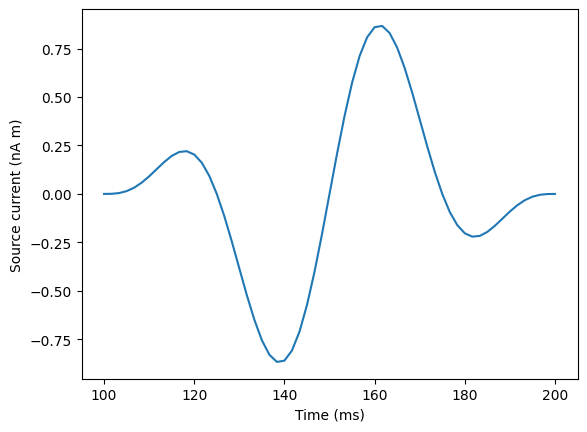

In [2]:
vertex = 22715          # Vertex on the original downsampled cortical surface
source_layer = "white"
snr_db = 0
seed = 16
window_ms = [100., 200.]

# Match the same anatomical vertex to its MSP prior and its column in the gain matrix.
prior, column = source_indices(vertex, vertex_ids, prepared)
_, time_ms, _ = load_meg_sensor_data(str(recording))
time_ms = np.round(time_ms, 8)  # Include the samples exactly at 100 and 200 ms.
active = (time_ms >= window_ms[0]) & (time_ms <= window_ms[1])
t = (time_ms[active] - window_ms[0]) / 1000.
duration = (window_ms[1] - window_ms[0]) / 1000.

# Apply a Hann envelope to bring the source current smoothly to zero at both ends.
current = np.zeros_like(time_ms)
current[active] = np.sin(2 * np.pi * 20 * t) * np.sin(np.pi * t / duration) ** 2
plt.plot(time_ms[active], current[active])
plt.xlabel("Time (ms)")
plt.ylabel("Source current (nA m)")
plt.show()

## Add sensor noise

Each gain column gives the sensor pattern for a unit source current. At 0 dB,
the signal and the added noise have equal RMS amplitude across sensors and
samples in the burst window.

In [3]:
gain_column = bem.layer(source_layer).gain[:, column]
signal = gain_column[:, None] * current[None, :]
noise = np.random.RandomState(seed).standard_normal(signal.shape)
signal_rms = np.sqrt(np.mean(signal[:, active] ** 2))
noise_rms = np.sqrt(np.mean(noise[:, active] ** 2))
sensor_data = signal + noise * (signal_rms / noise_rms) * 10 ** (-snr_db / 20)

## Compare the pial and white models

For each forward, fit a multiple sparse priors (MSP) inversion on each surface.
Use the same cortical vertex and time window for all four fits. SPM writes the inversion back to
the recording, so give each forward its own copy of the same simulated data.
For background on comparing cortical layers by free energy, see
[Bonaiuto et al. (2018)](https://doi.org/10.1016/j.neuroimage.2017.11.068).

In [4]:
# A 0.1 mm patch restricts the prior to the chosen vertex on these meshes.
settings = dict(priors=[prior], patch_size=0.1, woi=window_ms,
                n_spatial_modes="all", n_temp_modes=4)

# Give each run fresh SPM files so you can change the SNR and rerun this cell.
fit_dir = Path(mkdtemp(dir=work_dir))
evidence = {}
for name, forward in [("Single shell", single_shell), ("BEM", bem)]:
    dataset = write_evoked(recording, fit_dir / name / "simulation.mat",
                           bem.channel_names, sensor_data, spm)
    free_energy, _ = model_comparison(
        fids, str(dataset), prepared.surfaces, method="MSP", forward_operator=forward,
        invert_kwargs=settings, forward_kwargs={"iskull_fname": str(skull)},
        spm_instance=spm, viz=False,
    )
    # Match the energies to their surface names in the order returned by laMEG.
    evidence[name] = dict(zip(prepared.surfaces.get_layer_names(), np.ravel(free_energy)))

## Which layer did each model select?

Subtract the pial free energy from the white free energy. A positive difference
favors the simulated white source. A negative difference favors pial.

Single shell: -4.59
BEM: +7.87


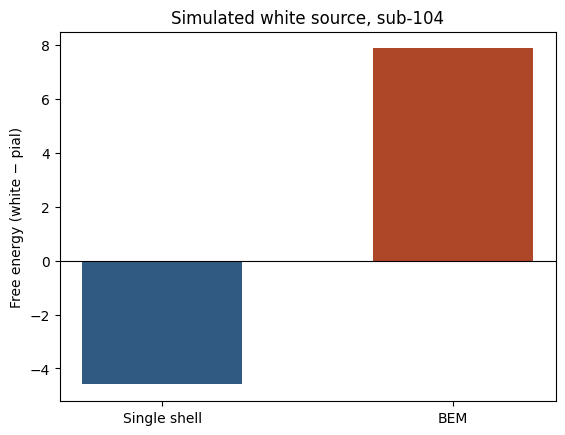

In [5]:
delta_f = {name: values["white"] - values["pial"] for name, values in evidence.items()}
for name, difference in delta_f.items():
    print(f"{name}: {difference:+.2f}")

plt.bar(list(delta_f), list(delta_f.values()), color=["#315a82", "#ae4628"], width=0.55)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Free energy (white − pial)")
plt.title("Simulated white source, sub-104")
plt.show()

With these settings, single shell favors pial (−4.59) and BEM recovers white
(+7.87). The same choices occurred with three fresh noise draws, although the
evidence was weaker on some draws. When single shell generated the white source
at this vertex and SNR, both inversions favored white on all three draws.

The [worked search and controls](https://github.com/danclab/laMEG/blob/9d8ed1dae7380367c9a990e9c32cc260f4e109af/tutorials/tutorial_10_single_shell_vs_bem.ipynb)
show how we chose this vertex and SNR.

To try another noise draw or SNR, change `seed` or `snr_db` and rerun from
the simulation step before closing SPM below.

In [6]:
spm.terminate()
workspace.cleanup()